# 💳 Credit Card Fraud Detection using Machine Learning

## Objective
Build an end-to-end machine learning model to detect fraudulent credit card transactions using supervised learning techniques.

### Algorithms
- Logistic Regression
- Random Forest
- XGBoost

### Tools & Libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Imbalanced-learn
- Joblib
- Streamlit

In [12]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)

from imblearn.over_sampling import SMOTE

import joblib

In [13]:
train = pd.read_csv("DATA/fraudTrain.csv")
test = pd.read_csv("DATA/fraudTest.csv")

print("Train Shape:", train.shape)
print("Test Shape :", test.shape)

Train Shape: (1296675, 23)
Test Shape : (555719, 23)


In [14]:
print("=" * 60)
print("TRAIN DATASET")
print("=" * 60)

print(f"Rows    : {train.shape[0]}")
print(f"Columns : {train.shape[1]}")

print("\nColumn Names:\n")
print(train.columns.tolist())

print("\nData Types:\n")
print(train.dtypes)

print("\nMissing Values:\n")
print(train.isnull().sum())

print("\nDuplicate Rows :", train.duplicated().sum())

TRAIN DATASET
Rows    : 1296675
Columns : 23

Column Names:

['Unnamed: 0', 'trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud']

Data Types:

Unnamed: 0                 int64
trans_date_trans_time        str
cc_num                     int64
merchant                     str
category                     str
amt                      float64
first                        str
last                         str
gender                       str
street                       str
city                         str
state                        str
zip                        int64
lat                      float64
long                     float64
city_pop                   int64
job                          str
dob                          str
trans_num                    str
unix_time                  int64
merch_lat        

In [15]:
train.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [16]:
train.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,1296675.0,NaN,NaN,NaN,648337.0,374317.974488,0.0,324168.5,648337.0,972505.5,1296674.0
trans_date_trans_time,1296675,1274791,2019-04-22 16:02:01,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cc_num,1296675.0,NaN,NaN,NaN,417192042079726656.0,1308806447000240384.0,60416207185.0,180042946491150.0,3521417320836166.0,4642255475285942.0,4992346398065154048.0
merchant,1296675,693,fraud_Kilback LLC,4403,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,1296675,14,gas_transport,131659,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amt,1296675.0,NaN,NaN,NaN,70.351035,160.316039,1.0,9.65,47.52,83.14,28948.9
first,1296675,352,Christopher,26669,NaN,NaN,NaN,NaN,NaN,NaN,NaN
last,1296675,481,Smith,28794,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,1296675,2,F,709863,NaN,NaN,NaN,NaN,NaN,NaN,NaN
street,1296675,983,864 Reynolds Plains,3123,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [17]:
train["is_fraud"].value_counts()

is_fraud
0    1289169
1       7506
Name: count, dtype: int64

In [18]:
fraud_percentage = train["is_fraud"].value_counts(normalize=True) * 100

print(fraud_percentage)

is_fraud
0    99.421135
1     0.578865
Name: proportion, dtype: float64


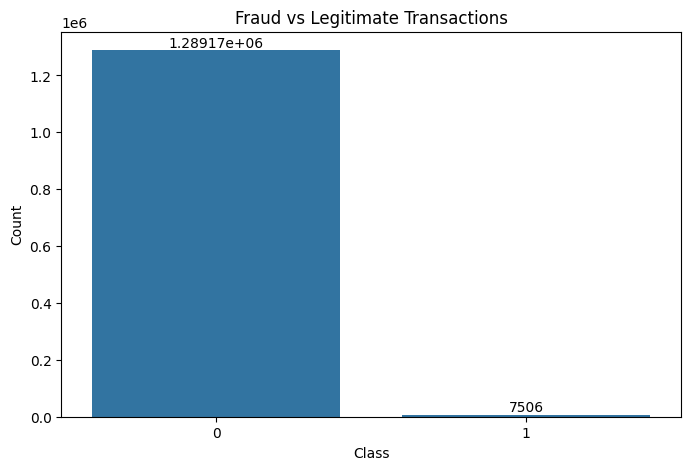

In [19]:
plt.figure(figsize=(8,5))

ax = sns.countplot(data=train, x="is_fraud")

for container in ax.containers:
    ax.bar_label(container)

plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Class")
plt.ylabel("Count")

plt.show()

## 1. Transaction Amount Analysis

This section analyzes the distribution of transaction amounts to understand spending patterns.

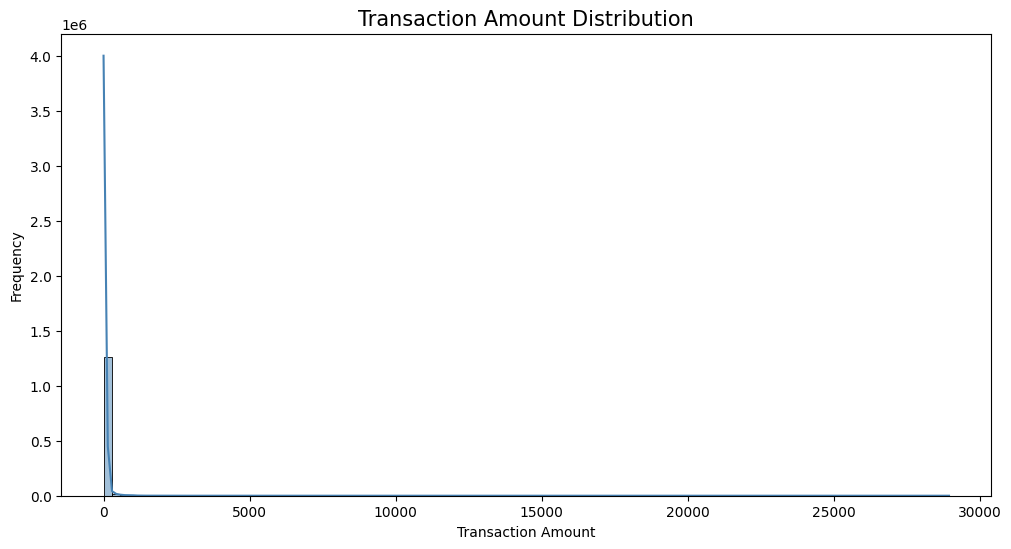

In [20]:
plt.figure(figsize=(12,6))

sns.histplot(train["amt"], bins=100, kde=True, color="steelblue")

plt.title("Transaction Amount Distribution", fontsize=15)
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

## 2. Fraud vs Transaction Amount

Compare transaction amounts for fraudulent and legitimate transactions.

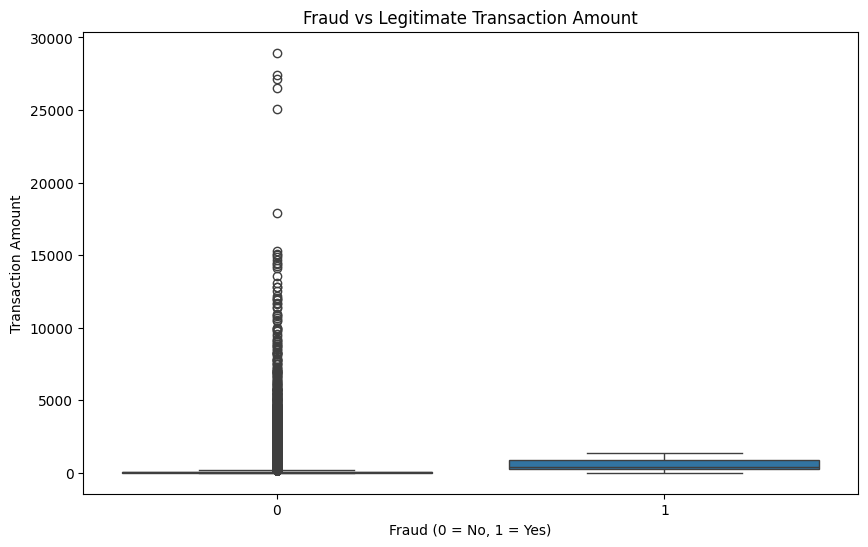

In [21]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=train,
    x="is_fraud",
    y="amt"
)

plt.title("Fraud vs Legitimate Transaction Amount")
plt.xlabel("Fraud (0 = No, 1 = Yes)")
plt.ylabel("Transaction Amount")

plt.show()

## 3. Gender-wise Fraud Analysis

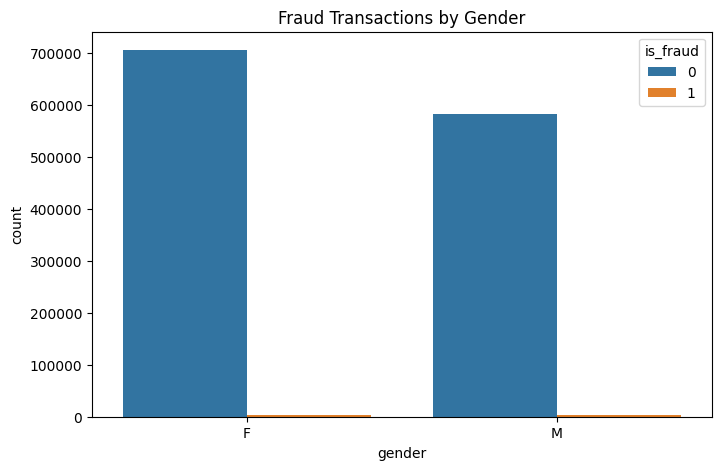

In [22]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=train,
    x="gender",
    hue="is_fraud"
)

plt.title("Fraud Transactions by Gender")

plt.show()

## 4. Top Merchant Categories

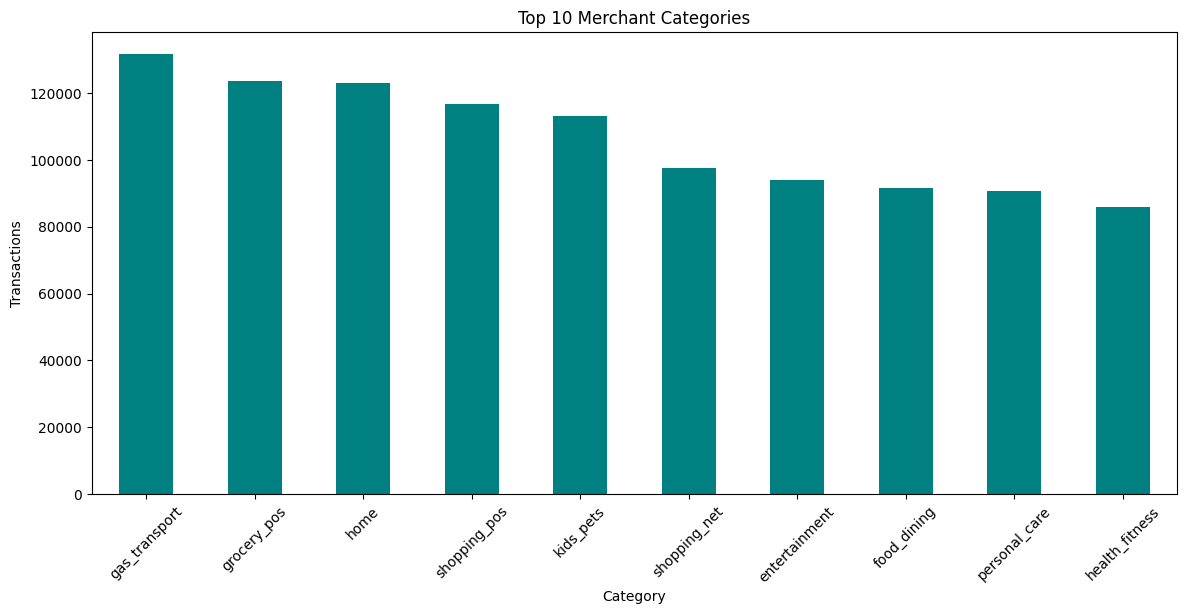

In [23]:
plt.figure(figsize=(14,6))

train["category"].value_counts().head(10).plot(
    kind="bar",
    color="teal"
)

plt.title("Top 10 Merchant Categories")
plt.xlabel("Category")
plt.ylabel("Transactions")

plt.xticks(rotation=45)

plt.show()

## 5. Top States by Transactions

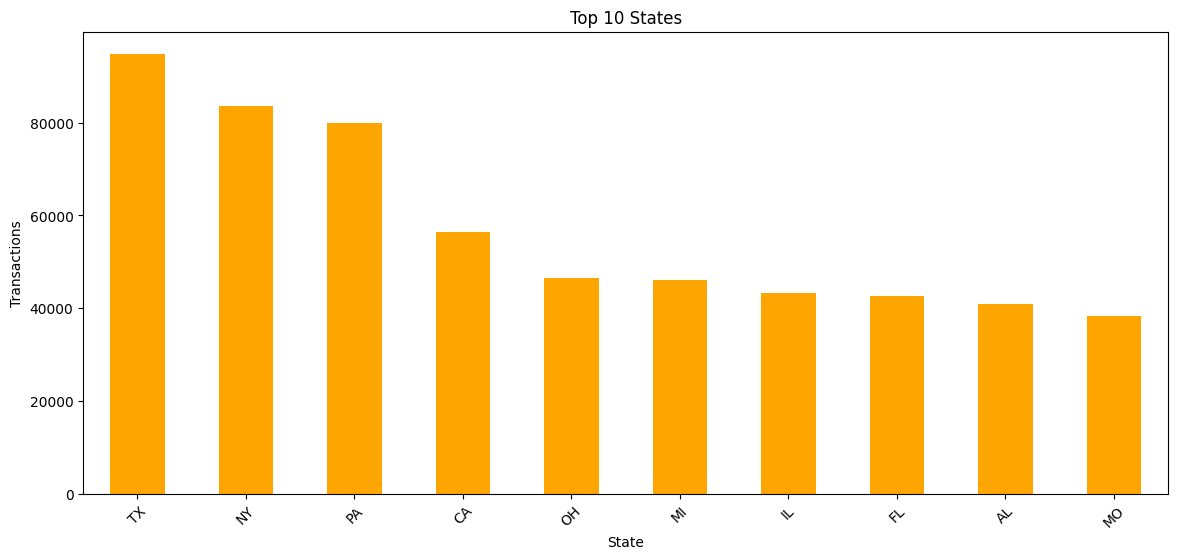

In [24]:
plt.figure(figsize=(14,6))

train["state"].value_counts().head(10).plot(
    kind="bar",
    color="orange"
)

plt.title("Top 10 States")
plt.xlabel("State")
plt.ylabel("Transactions")

plt.xticks(rotation=45)

plt.show()

## 6. Customer Age Distribution

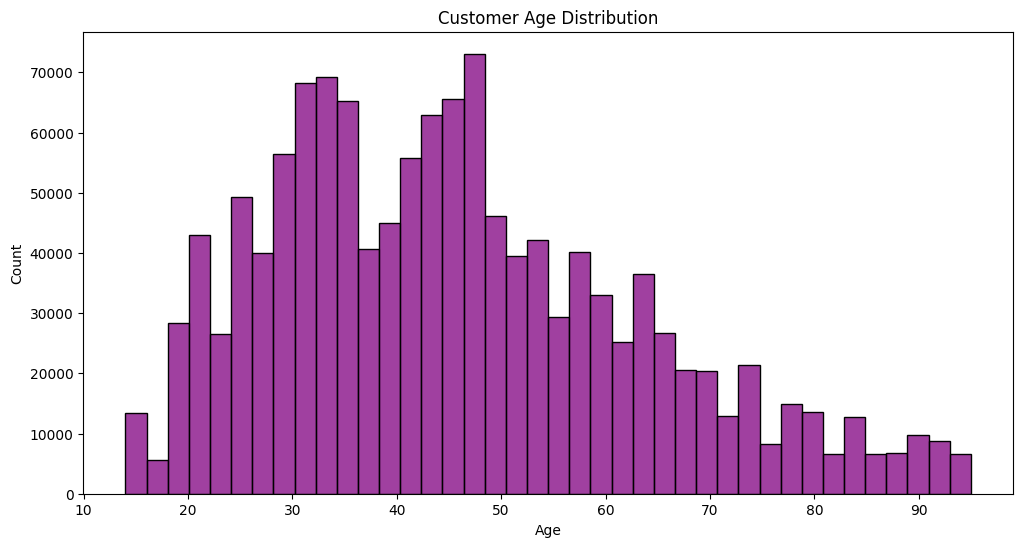

In [25]:
train["dob"] = pd.to_datetime(train["dob"])

train["customer_age"] = 2019 - train["dob"].dt.year

plt.figure(figsize=(12,6))

sns.histplot(
    train["customer_age"],
    bins=40,
    color="purple"
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")

plt.show()

## 7. Transactions by Hour

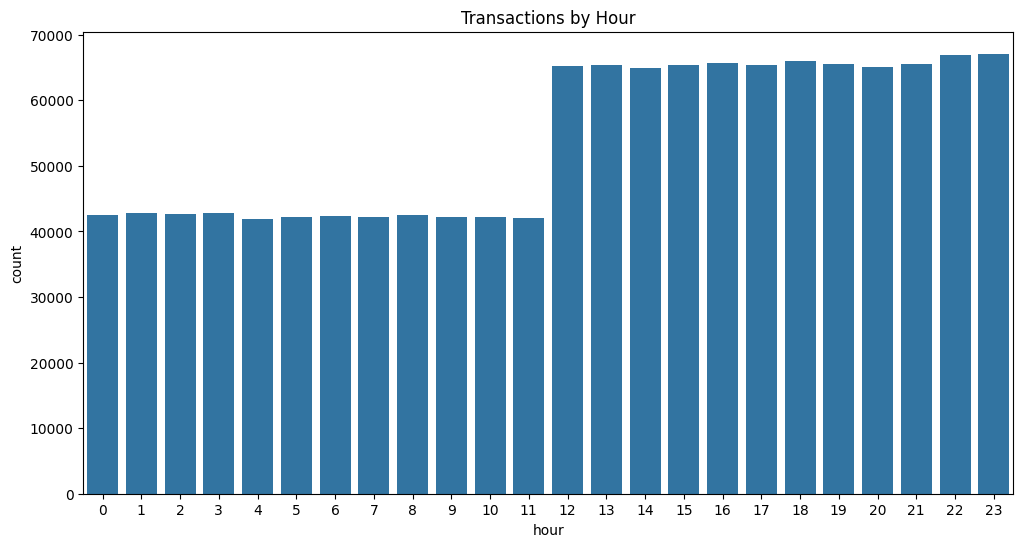

In [26]:
train["trans_date_trans_time"] = pd.to_datetime(train["trans_date_trans_time"])

train["hour"] = train["trans_date_trans_time"].dt.hour

plt.figure(figsize=(12,6))

sns.countplot(
    data=train,
    x="hour"
)

plt.title("Transactions by Hour")

plt.show()

## 8. Correlation Matrix

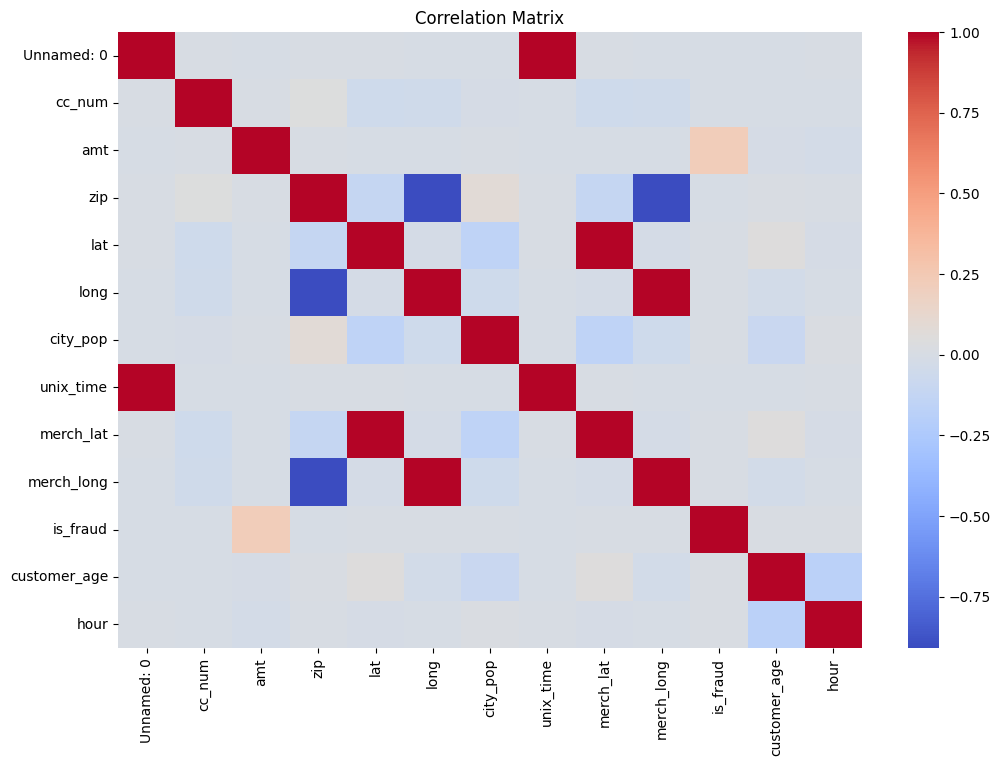

In [27]:
numeric = train.select_dtypes(include=["number"])

corr = numeric.corr()

plt.figure(figsize=(12,8))

sns.heatmap(
    corr,
    cmap="coolwarm",
    annot=False
)

plt.title("Correlation Matrix")

plt.show()

# Data Preprocessing

In this section, the dataset is cleaned and transformed before training the machine learning models.

In [28]:
# Create a copy of dataset

train_df = train.copy()
test_df = test.copy()

print("Copy Created Successfully")

Copy Created Successfully


In [29]:
drop_cols = [
    "Unnamed: 0",
    "trans_date_trans_time",
    "cc_num",
    "first",
    "last",
    "street",
    "city",
    "state",
    "zip",
    "dob",
    "trans_num"
]

train_df.drop(columns=drop_cols, inplace=True)
test_df.drop(columns=drop_cols, inplace=True)

print(train_df.shape)
print(test_df.shape)

(1296675, 14)
(555719, 12)


In [30]:
print(train_df.isnull().sum())

merchant        0
category        0
amt             0
gender          0
lat             0
long            0
city_pop        0
job             0
unix_time       0
merch_lat       0
merch_long      0
is_fraud        0
customer_age    0
hour            0
dtype: int64


In [31]:
from sklearn.preprocessing import OrdinalEncoder

categorical_cols = train_df.select_dtypes(include=["object"]).columns

encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

train_df[categorical_cols] = encoder.fit_transform(train_df[categorical_cols])
test_df[categorical_cols] = encoder.transform(test_df[categorical_cols])

print("Encoding Completed Successfully")

Encoding Completed Successfully


In [33]:
import os

os.makedirs("DATA", exist_ok=True)

train_df.to_csv("DATA/train_processed.csv", index=False)
test_df.to_csv("DATA/test_processed.csv", index=False)

# Model Training

In this section, we train multiple machine learning models to classify fraudulent transactions. The performance of each model will be evaluated using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.

In [34]:
import pandas as pd

train_df = pd.read_csv("DATA/train_processed.csv")
test_df = pd.read_csv("DATA/test_processed.csv")

print(train_df.shape)
print(test_df.shape)

(1296675, 14)
(555719, 12)


In [35]:
X_train = train_df.drop("is_fraud", axis=1)
y_train = train_df["is_fraud"]

X_test = test_df.drop("is_fraud", axis=1)
y_test = test_df["is_fraud"]

print(X_train.shape)
print(X_test.shape)

(1296675, 13)
(555719, 11)


In [40]:
train_df = pd.read_csv("DATA/train_processed.csv")
test_df = pd.read_csv("DATA/test_processed.csv")

print(train_df.columns)
print(test_df.columns)

Index(['merchant', 'category', 'amt', 'gender', 'lat', 'long', 'city_pop',
       'job', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud',
       'customer_age', 'hour'],
      dtype='str')
Index(['merchant', 'category', 'amt', 'gender', 'lat', 'long', 'city_pop',
       'job', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud'],
      dtype='str')


In [41]:
# Add missing columns in test_df

test["dob"] = pd.to_datetime(test["dob"])
test["customer_age"] = 2019 - test["dob"].dt.year

test["trans_date_trans_time"] = pd.to_datetime(test["trans_date_trans_time"])
test["hour"] = test["trans_date_trans_time"].dt.hour

In [42]:
drop_cols = [
    "Unnamed: 0",
    "trans_date_trans_time",
    "cc_num",
    "first",
    "last",
    "street",
    "city",
    "state",
    "zip",
    "dob",
    "trans_num"
]

test_df = test.copy()
test_df.drop(columns=drop_cols, inplace=True)

In [43]:
test_df.to_csv("DATA/test_processed.csv", index=False)

In [44]:
train_df = pd.read_csv("DATA/train_processed.csv")
test_df = pd.read_csv("DATA/test_processed.csv")

print(train_df.columns)
print(test_df.columns)

Index(['merchant', 'category', 'amt', 'gender', 'lat', 'long', 'city_pop',
       'job', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud',
       'customer_age', 'hour'],
      dtype='str')
Index(['merchant', 'category', 'amt', 'gender', 'lat', 'long', 'city_pop',
       'job', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud',
       'customer_age', 'hour'],
      dtype='str')


In [47]:
import pandas as pd

# Original datasets load karo
train = pd.read_csv("DATA/fraudTrain.csv")
test = pd.read_csv("DATA/fraudTest.csv")

# Customer Age
train["dob"] = pd.to_datetime(train["dob"])
test["dob"] = pd.to_datetime(test["dob"])

train["customer_age"] = 2019 - train["dob"].dt.year
test["customer_age"] = 2019 - test["dob"].dt.year

# Hour Feature
train["trans_date_trans_time"] = pd.to_datetime(train["trans_date_trans_time"])
test["trans_date_trans_time"] = pd.to_datetime(test["trans_date_trans_time"])

train["hour"] = train["trans_date_trans_time"].dt.hour
test["hour"] = test["trans_date_trans_time"].dt.hour

drop_cols = [
    "Unnamed: 0",
    "trans_date_trans_time",
    "cc_num",
    "first",
    "last",
    "street",
    "city",
    "state",
    "zip",
    "dob",
    "trans_num"
]

train_df = train.drop(columns=drop_cols)
test_df = test.drop(columns=drop_cols)

print(train_df.shape)
print(test_df.shape)
print(train_df.columns.equals(test_df.columns))

(1296675, 14)
(555719, 14)
True


In [49]:
print(X_train.dtypes)

merchant            str
category            str
amt             float64
gender              str
lat             float64
long            float64
city_pop          int64
job                 str
unix_time         int64
merch_lat       float64
merch_long      float64
customer_age      int32
hour              int32
dtype: object


In [51]:
print(X_train.isnull().sum().sort_values(ascending=False).head(10))

merchant     0
category     0
amt          0
gender       0
lat          0
long         0
city_pop     0
job          0
unix_time    0
merch_lat    0
dtype: int64


In [53]:
print(X_train.select_dtypes(exclude=["number"]).columns)

Index(['merchant', 'category', 'gender', 'job'], dtype='str')


In [55]:
train_df.to_csv("DATA/train_processed.csv", index=False)
test_df.to_csv("DATA/test_processed.csv", index=False)

In [56]:
# Check processed data
print(train_df.shape)
print(test_df.shape)

train_df.head()

(1296675, 14)
(555719, 14)


,merchant,category,amt,gender,lat,long,city_pop,job,unix_time,merch_lat,merch_long,is_fraud,customer_age,hour
0,"fraud_Rippin, Kub and Mann",misc_net,4.97,F,36.0788,-81.1781,3495,"Psychologist, counselling",1325376018,36.011293,-82.048315,0,31,0
1,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,F,48.8878,-118.2105,149,Special educational needs teacher,1325376044,49.159047,-118.186462,0,41,0
2,fraud_Lind-Buckridge,entertainment,220.11,M,42.1808,-112.2620,4154,Nature conservation officer,1325376051,43.150704,-112.154481,0,57,0
3,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,M,46.2306,-112.1138,1939,Patent attorney,1325376076,47.034331,-112.561071,0,52,0
4,fraud_Keeling-Crist,misc_pos,41.96,M,38.4207,-79.4629,99,Dance movement psychotherapist,1325376186,38.674999,-78.632459,0,33,0


In [58]:
train_df.columns


Index(['merchant', 'category', 'amt', 'gender', 'lat', 'long', 'city_pop',
       'job', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud',
       'customer_age', 'hour'],
      dtype='str')

In [8]:
import pandas as pd
import os

print(os.listdir("DATA"))

['fraudTest.csv', 'fraudTrain.csv', 'test_processed.csv', 'train_processed.csv']


In [10]:
import pandas as pd

print(os.listdir("DATA"))

['fraudTest.csv', 'fraudTrain.csv', 'test_processed.csv', 'train_processed.csv']


In [11]:
import pandas as pd

# Load original datasets
train_df = pd.read_csv("DATA/fraudTrain.csv")
test_df = pd.read_csv("DATA/fraudTest.csv")

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("\nColumns:")
print(train_df.columns.tolist())

print("\nFirst 5 rows:")
display(train_df.head())

Train shape: (1296675, 23)
Test shape: (555719, 23)

Columns:
['Unnamed: 0', 'trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud']

First 5 rows:


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [12]:
# Check target and missing values

print("Target column values:")
print(train_df["is_fraud"].value_counts())

print("\nMissing values:")
print(train_df.isnull().sum())

print("\nData types:")
print(train_df.dtypes)

Target column values:
is_fraud
0    1289169
1       7506
Name: count, dtype: int64

Missing values:
Unnamed: 0               0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64

Data types:
Unnamed: 0                 int64
trans_date_trans_time        str
cc_num                     int64
merchant                     str
category                     str
amt                      float64
first                        str
last                  

In [13]:
# ==========================================
# STEP 3 - PREPROCESSING
# ==========================================

import pandas as pd

# Copy original data
df = train_df.copy()

# ------------------------------------------
# 1. Remove unnecessary columns
# ------------------------------------------

df = df.drop([
    "Unnamed: 0",
    "cc_num",
    "first",
    "last",
    "street",
    "zip"
], axis=1)

# ------------------------------------------
# 2. Convert date/time
# ------------------------------------------

df["trans_date_trans_time"] = pd.to_datetime(
    df["trans_date_trans_time"]
)

# Extract useful time features
df["hour"] = df["trans_date_trans_time"].dt.hour
df["day"] = df["trans_date_trans_time"].dt.day
df["month"] = df["trans_date_trans_time"].dt.month
df["day_of_week"] = df["trans_date_trans_time"].dt.dayofweek

# Remove original datetime
df = df.drop("trans_date_trans_time", axis=1)

# ------------------------------------------
# 3. Convert DOB to age
# ------------------------------------------

df["dob"] = pd.to_datetime(df["dob"])

df["age"] = (
    pd.Timestamp("2026-01-01") - df["dob"]
).dt.days / 365.25

df["age"] = df["age"].astype("float32")

df = df.drop("dob", axis=1)

# ------------------------------------------
# 4. Separate target
# ------------------------------------------

y = df["is_fraud"]
X = df.drop("is_fraud", axis=1)

# ------------------------------------------
# 5. Remove high-cardinality columns
# ------------------------------------------

X = X.drop([
    "merchant",
    "job",
    "city"
], axis=1)

# ------------------------------------------
# 6. One-hot encode categorical columns
# ------------------------------------------

X = pd.get_dummies(
    X,
    columns=["category", "gender", "state"],
    dtype="float32"
)

# ------------------------------------------
# 7. Final check
# ------------------------------------------

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

print("\nFirst 5 rows:")
display(X.head())

X shape: (1296675, 80)
y shape: (1296675,)

Target distribution:
is_fraud
0    1289169
1       7506
Name: count, dtype: int64

First 5 rows:


,amt,lat,long,city_pop,trans_num,unix_time,merch_lat,merch_long,hour,day,...,state_SD,state_TN,state_TX,state_UT,state_VA,state_VT,state_WA,state_WI,state_WV,state_WY
0,4.97,36.0788,-81.1781,3495,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,107.23,48.8878,-118.2105,149,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,220.11,42.1808,-112.2620,4154,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,45.00,46.2306,-112.1138,1939,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,41.96,38.4207,-79.4629,99,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0,1,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [15]:
# ==========================================
# FIX trans_num + TRAIN MODEL
# ==========================================

# Remove transaction number because it is text
X = X.drop("trans_num", axis=1)

print("New X shape:", X.shape)

# ------------------------------------------
# Take sample
# ------------------------------------------

X_sample = X.sample(
    n=100000,
    random_state=42
)

y_sample = y.loc[X_sample.index]

# ------------------------------------------
# Split
# ------------------------------------------

X_train, X_val, y_train, y_val = train_test_split(
    X_sample,
    y_sample,
    test_size=0.20,
    random_state=42,
    stratify=y_sample
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

# ------------------------------------------
# Model
# ------------------------------------------

model = RandomForestClassifier(
    n_estimators=30,
    max_depth=10,
    random_state=42,
    n_jobs=1,
    class_weight="balanced"
)

# ------------------------------------------
# Train
# ------------------------------------------

print("\nTraining started...")

model.fit(X_train, y_train)

print("Training completed!")

# ------------------------------------------
# Prediction
# ------------------------------------------

y_pred = model.predict(X_val)

# ------------------------------------------
# Results
# ------------------------------------------

print("\n========== MODEL RESULTS ==========")

print("Accuracy :", accuracy_score(y_val, y_pred))
print("Precision:", precision_score(y_val, y_pred, zero_division=0))
print("Recall   :", recall_score(y_val, y_pred, zero_division=0))
print("F1 Score :", f1_score(y_val, y_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(y_val, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_pred))

New X shape: (1296675, 79)
Training: (80000, 79)
Validation: (20000, 79)

Training started...
Training completed!

========== MODEL RESULTS ==========
Accuracy : 0.9913
Precision: 0.38461538461538464
Recall   : 0.75
F1 Score : 0.5084745762711864

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00     19880
           1       0.38      0.75      0.51       120

    accuracy                           0.99     20000
   macro avg       0.69      0.87      0.75     20000
weighted avg       0.99      0.99      0.99     20000


Confusion Matrix:
[[19736   144]
 [   30    90]]


In [16]:
# ==========================================
# STEP 5 - TEST DATA PREDICTION
# ==========================================

# Load test data
test_df = pd.read_csv("DATA/fraudTest.csv")

print("Test data shape:", test_df.shape)

# Keep original copy for final results
test_result = test_df.copy()

# ------------------------------------------
# 1. Same preprocessing as training
# ------------------------------------------

test_X = test_df.copy()

test_X = test_X.drop([
    "Unnamed: 0",
    "cc_num",
    "first",
    "last",
    "street",
    "zip"
], axis=1)

# Date/time
test_X["trans_date_trans_time"] = pd.to_datetime(
    test_X["trans_date_trans_time"]
)

test_X["hour"] = test_X["trans_date_trans_time"].dt.hour
test_X["day"] = test_X["trans_date_trans_time"].dt.day
test_X["month"] = test_X["trans_date_trans_time"].dt.month
test_X["day_of_week"] = test_X["trans_date_trans_time"].dt.dayofweek

test_X = test_X.drop("trans_date_trans_time", axis=1)

# DOB → age
test_X["dob"] = pd.to_datetime(test_X["dob"])

test_X["age"] = (
    pd.Timestamp("2026-01-01") - test_X["dob"]
).dt.days / 365.25

test_X["age"] = test_X["age"].astype("float32")

test_X = test_X.drop("dob", axis=1)

# Remove target
test_X = test_X.drop("is_fraud", axis=1)

# Remove high-cardinality columns
test_X = test_X.drop([
    "merchant",
    "job",
    "city"
], axis=1)

# One-hot encoding
test_X = pd.get_dummies(
    test_X,
    columns=["category", "gender", "state"],
    dtype="float32"
)

# Remove transaction ID
test_X = test_X.drop("trans_num", axis=1)

# Make columns exactly same as training data
test_X = test_X.reindex(
    columns=X.columns,
    fill_value=0
)

print("Processed test shape:", test_X.shape)

# ------------------------------------------
# 2. Prediction
# ------------------------------------------

test_predictions = model.predict(test_X)

# ------------------------------------------
# 3. Add predictions
# ------------------------------------------

test_result["predicted_fraud"] = test_predictions

# ------------------------------------------
# 4. Results
# ------------------------------------------

print("\nPrediction completed!")

print("\nPredicted classes:")
print(
    pd.Series(test_predictions).value_counts()
)

print("\nPredicted fraud transactions:",
      (test_predictions == 1).sum())

# ------------------------------------------
# 5. Save predictions
# ------------------------------------------

test_result.to_csv(
    "DATA/fraud_predictions.csv",
    index=False
)

print("\nSaved successfully:")
print("DATA/fraud_predictions.csv")

Test data shape: (555719, 23)
Processed test shape: (555719, 79)

Prediction completed!

Predicted classes:
0    550528
1      5191
Name: count, dtype: int64

Predicted fraud transactions: 5191

Saved successfully:
DATA/fraud_predictions.csv


In [17]:
# ==========================================
# STEP 6 - FINAL TEST PERFORMANCE
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Actual test target
y_test = test_df["is_fraud"]

# Model predictions
y_test_pred = test_result["predicted_fraud"]

# Results
print("========== FINAL TEST RESULTS ==========")

print("Accuracy :", accuracy_score(y_test, y_test_pred))
print("Precision:", precision_score(y_test, y_test_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_test_pred, zero_division=0))
print("F1 Score :", f1_score(y_test, y_test_pred, zero_division=0))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

========== FINAL TEST RESULTS ==========
Accuracy : 0.9922622764382718
Precision: 0.2924292043922173
Recall   : 0.7076923076923077
F1 Score : 0.4138495092693566

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00    553574
           1       0.29      0.71      0.41      2145

    accuracy                           0.99    555719
   macro avg       0.65      0.85      0.70    555719
weighted avg       1.00      0.99      0.99    555719


Confusion Matrix:
[[549901   3673]
 [   627   1518]]


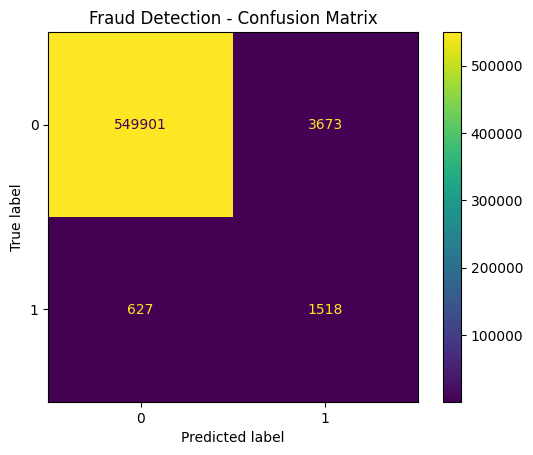

In [18]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred
)

plt.title("Fraud Detection - Confusion Matrix")
plt.show()

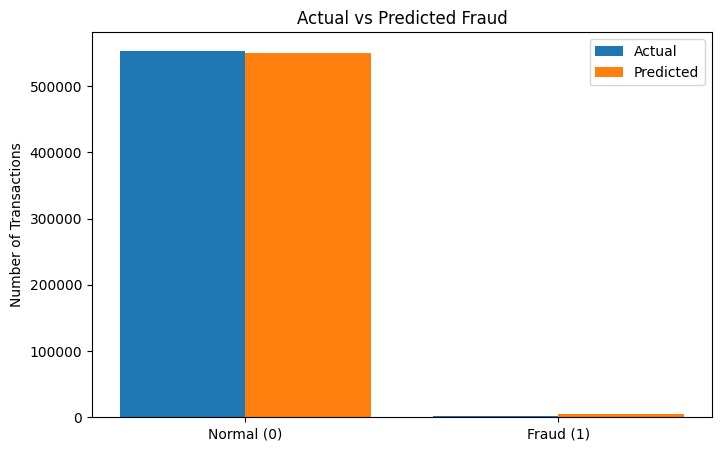

In [19]:
import matplotlib.pyplot as plt

actual_counts = y_test.value_counts().sort_index()
predicted_counts = pd.Series(y_test_pred).value_counts().sort_index()

labels = ["Normal (0)", "Fraud (1)"]

actual = [
    actual_counts.get(0, 0),
    actual_counts.get(1, 0)
]

predicted = [
    predicted_counts.get(0, 0),
    predicted_counts.get(1, 0)
]

x = range(len(labels))

plt.figure(figsize=(8, 5))

plt.bar(
    [i - 0.2 for i in x],
    actual,
    width=0.4,
    label="Actual"
)

plt.bar(
    [i + 0.2 for i in x],
    predicted,
    width=0.4,
    label="Predicted"
)

plt.xticks(list(x), labels)
plt.ylabel("Number of Transactions")
plt.title("Actual vs Predicted Fraud")
plt.legend()

plt.show()

In [20]:
import joblib

# Save trained model
joblib.dump(model, "DATA/fraud_detection_model.pkl")

print("Model saved successfully!")
print("File: DATA/fraud_detection_model.pkl")

Model saved successfully!
File: DATA/fraud_detection_model.pkl


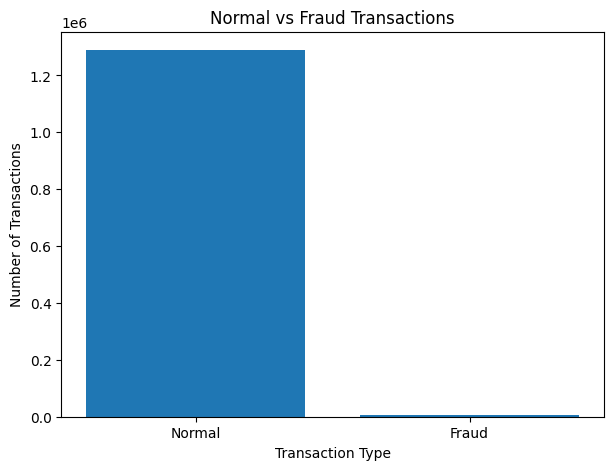

In [21]:
import matplotlib.pyplot as plt


fraud_counts = train_df["is_fraud"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(
    ["Normal", "Fraud"],
    [fraud_counts[0], fraud_counts[1]]
)

plt.title("Normal vs Fraud Transactions")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.show()

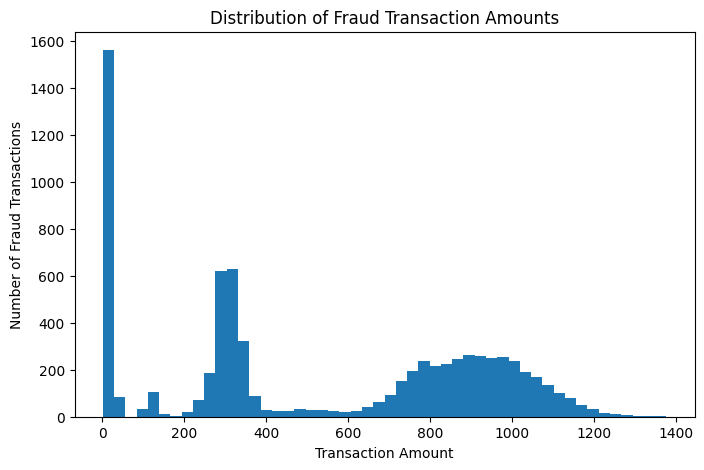

In [ ]:
fraud_data = train_df[train_df["is_fraud"] == 1]

plt.figure(figsize=(8, 5))

plt.hist(
    fraud_data["amt"],
    bins=50
)

plt.title("Distribution of Fraud Transaction Amounts")
plt.xlabel("Transaction Amount")
plt.ylabel("Number of Fraud Transactions")

plt.show()

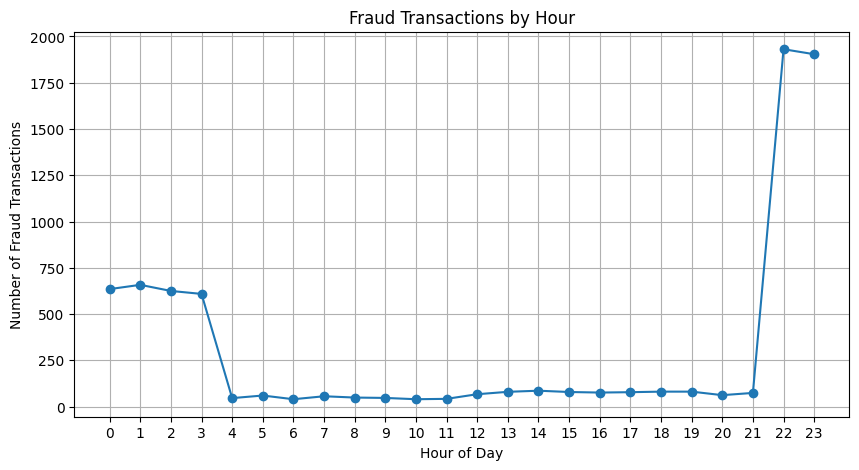

In [24]:
train_df["trans_date_trans_time"] = pd.to_datetime(
    train_df["trans_date_trans_time"]
)

train_df["hour"] = train_df["trans_date_trans_time"].dt.hour

# Fraud transactions by hour

fraud_by_hour = (
    train_df[train_df["is_fraud"] == 1]
    .groupby("hour")
    .size()
)

plt.figure(figsize=(10, 5))

plt.plot(
    fraud_by_hour.index,
    fraud_by_hour.values,
    marker="o"
)

plt.title("Fraud Transactions by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Fraud Transactions")
plt.xticks(range(24))

plt.grid(True)
plt.show()

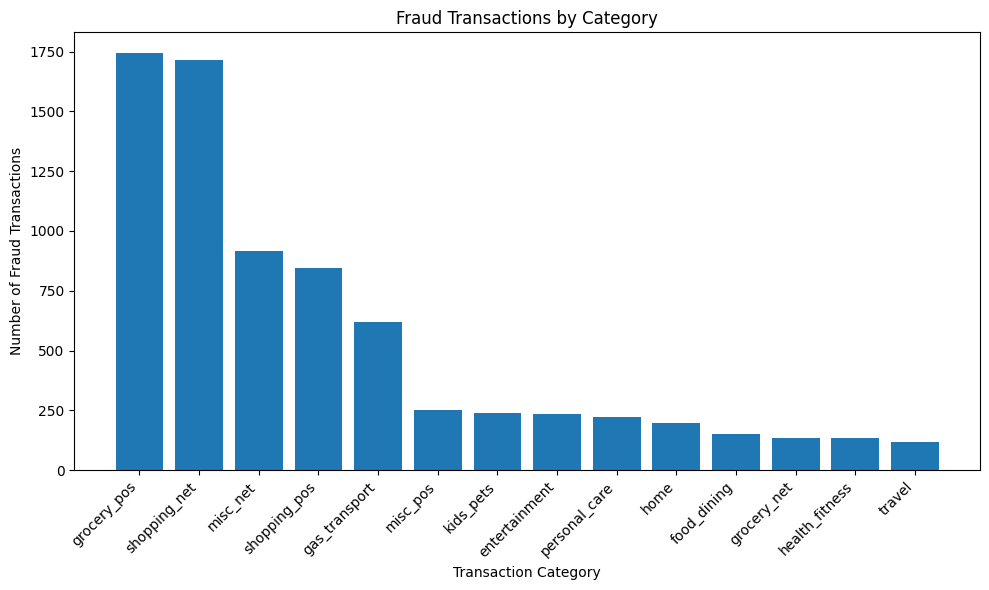

In [25]:
fraud_by_category = (
    train_df[train_df["is_fraud"] == 1]
    .groupby("category")
    .size()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

plt.bar(
    fraud_by_category.index,
    fraud_by_category.values
)

plt.title("Fraud Transactions by Category")
plt.xlabel("Transaction Category")
plt.ylabel("Number of Fraud Transactions")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()